In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Find the project root from the notebooks folder
PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.rainfall_model import (
    Region,
    CropRule,
    cosine_similarity,
    verify_cosine_similarity,
    region_comparison,
    detect_rainy_seasons,
    suitability_table,
    MONTHS,
)

print("Mini-Project 4 loaded successfully.")


Mini-Project 4 loaded successfully.


# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

## Objective

This project analyses monthly rainfall patterns for Kampala, Gulu and
Mbarara. It compares regional rainfall regimes, evaluates simplified crop
suitability, measures similarity between regions, detects rainfall peaks,
and provides a farmer advisory.

The supplied rainfall data are illustrative synthetic data. Therefore,
the conclusions should be interpreted as a demonstration of the analytical
methods rather than as official climate or agricultural advice.


In [8]:
kampala = Region(
    name="Kampala",
    rainfall=np.array([
        120, 140, 180, 200, 220, 180,
        90, 70, 60, 100, 110, 130
    ])
)

gulu = Region(
    name="Gulu",
    rainfall=np.array([
        8, 25, 75, 160, 190, 145,
        170, 215, 175, 150, 60, 15
    ])
)

mbarara = Region(
    name="Mbarara",
    rainfall=np.array([
        70, 85, 120, 140, 90, 25,
        20, 55, 100, 125, 120, 90
    ])
)

regions = [
    kampala,
    gulu,
    mbarara
]

print("Regions created:")

for region in regions:
    print("-", region.name)


Regions created:
- Kampala
- Gulu
- Mbarara


In [9]:
summary_rows = []

for region in regions:
    summary = region.summary()

    summary_rows.append({
        "Region": region.name,
        "Annual total (mm)": summary["annual_total"],
        "Monthly mean (mm)": summary["monthly_mean"],
        "Wettest month": summary["wettest_month"],
        "Driest month": summary["driest_month"],
        "CV": summary["cv"],
    })

summary_df = pd.DataFrame(summary_rows)

display(
    summary_df.round({
        "Annual total (mm)": 2,
        "Monthly mean (mm)": 2,
        "CV": 3
    })
)


,Region,Annual total (mm),Monthly mean (mm),Wettest month,Driest month,CV
0,Kampala,1600.0,133.33,May,Sep,0.388
1,Gulu,1388.0,115.67,Aug,Jan,0.642
2,Mbarara,1040.0,86.67,Apr,Jul,0.444


## Coefficient of Variation

The coefficient of variation (CV) is calculated as:

CV = standard deviation / mean

It is useful for comparing rainfall variability between regions because it
expresses standard deviation relative to the mean rainfall. A larger CV
indicates greater variability relative to the region's average rainfall.


In [10]:
maize = CropRule(
    crop="Maize",
    minimum_rainfall=50,
    maximum_rainfall=200
)

beans = CropRule(
    crop="Beans",
    minimum_rainfall=40,
    maximum_rainfall=150
)

coffee = CropRule(
    crop="Coffee",
    minimum_rainfall=100,
    maximum_rainfall=250
)

crops = [
    maize,
    beans,
    coffee
]

for crop in crops:
    print(
        crop.crop,
        ":",
        crop.minimum_rainfall,
        "-",
        crop.maximum_rainfall,
        "mm/month"
    )


Maize : 50 - 200 mm/month
Beans : 40 - 150 mm/month
Coffee : 100 - 250 mm/month


In [11]:
suitability = suitability_table(
    regions,
    crops
)

for region_name, crop_results in suitability.items():

    print("\n" + "=" * 50)
    print(region_name)
    print("=" * 50)

    for crop_name, classifications in crop_results.items():

        print(f"\n{crop_name}")

        for month, classification in zip(
            MONTHS,
            classifications
        ):
            print(
                f"{month}: {classification}"
            )



Kampala

Maize
Jan: Good
Feb: Good
Mar: Good
Apr: Good
May: Waterlogging risk
Jun: Good
Jul: Good
Aug: Good
Sep: Good
Oct: Good
Nov: Good
Dec: Good

Beans
Jan: Good
Feb: Good
Mar: Waterlogging risk
Apr: Waterlogging risk
May: Waterlogging risk
Jun: Waterlogging risk
Jul: Good
Aug: Good
Sep: Good
Oct: Good
Nov: Good
Dec: Good

Coffee
Jan: Good
Feb: Good
Mar: Good
Apr: Good
May: Good
Jun: Good
Jul: Drought risk
Aug: Drought risk
Sep: Drought risk
Oct: Good
Nov: Good
Dec: Good

Gulu

Maize
Jan: Drought risk
Feb: Drought risk
Mar: Good
Apr: Good
May: Good
Jun: Good
Jul: Good
Aug: Waterlogging risk
Sep: Good
Oct: Good
Nov: Good
Dec: Drought risk

Beans
Jan: Drought risk
Feb: Drought risk
Mar: Good
Apr: Waterlogging risk
May: Waterlogging risk
Jun: Good
Jul: Waterlogging risk
Aug: Waterlogging risk
Sep: Waterlogging risk
Oct: Good
Nov: Good
Dec: Drought risk

Coffee
Jan: Drought risk
Feb: Drought risk
Mar: Drought risk
Apr: Good
May: Good
Jun: Good
Jul: Good
Aug: Good
Sep: Good
Oct: Good
No

In [12]:
suitability_rows = []

for region_name, crop_results in suitability.items():
    for crop_name, classifications in crop_results.items():
        for month, classification in zip(MONTHS, classifications):
            suitability_rows.append({
                "Region": region_name,
                "Crop": crop_name,
                "Month": month,
                "Suitability": classification
            })

suitability_df = pd.DataFrame(suitability_rows)

display(suitability_df)


,Region,Crop,Month,Suitability
0,Kampala,Maize,Jan,Good
1,Kampala,Maize,Feb,Good
2,Kampala,Maize,Mar,Good
3,Kampala,Maize,Apr,Good
4,Kampala,Maize,May,Waterlogging risk
...,...,...,...,...
103,Mbarara,Coffee,Aug,Drought risk
104,Mbarara,Coffee,Sep,Good
105,Mbarara,Coffee,Oct,Good
106,Mbarara,Coffee,Nov,Good


In [13]:
# Calculate cosine similarity between Kampala and Gulu
kampala_gulu_similarity = cosine_similarity(
    kampala.rainfall,
    gulu.rainfall
)

print(
    f"Cosine similarity between Kampala and Gulu: "
    f"{kampala_gulu_similarity:.4f}"
)

# Verify our implementation against SciPy
verification = verify_cosine_similarity(
    kampala.rainfall,
    gulu.rainfall
)

print("\nSciPy verification:")
print(verification)

print("\nThe NumPy and SciPy results should agree.")


Cosine similarity between Kampala and Gulu: 0.7866

SciPy verification:
{'our_similarity': 0.7866089874660105, 'scipy_similarity': 0.7866089874660105, 'absolute_difference': np.float64(0.0)}

The NumPy and SciPy results should agree.


In [14]:
comparison = region_comparison(regions)

print("COSINE SIMILARITY")
display(comparison["cosine"].round(4))

print("\nPEARSON CORRELATION")
display(comparison["pearson"].round(4))

print("\nEUCLIDEAN DISTANCE")
display(comparison["euclidean"].round(2))


COSINE SIMILARITY


array([[1.    , 0.7866, 0.8912],
       [0.7866, 1.    , 0.7487],
       [0.8912, 0.7487, 1.    ]])


PEARSON CORRELATION


array([[ 1.    , -0.0664,  0.2093],
       [-0.0664,  1.    , -0.1739],
       [ 0.2093, -0.1739,  1.    ]])


EUCLIDEAN DISTANCE


array([[  0.  , 315.27, 250.4 ],
       [315.27,   0.  , 312.8 ],
       [250.4 , 312.8 ,   0.  ]])

## Task 4: Comparing Rainfall Patterns

Cosine similarity measures the angle between two rainfall vectors rather than
their absolute size. Therefore, two regions can have a high cosine similarity
if their rainfall rises and falls in similar proportions, even when one region
receives substantially more rainfall than the other.

Pearson correlation focuses on whether the monthly rainfall patterns move
together. It is relatively insensitive to differences in overall rainfall
magnitude.

Euclidean distance uses the actual numerical differences between rainfall
values. A wetter region can therefore have a large Euclidean distance from a
drier region even if their seasonal patterns are similar.

Using all three measures gives a more complete comparison of the rainfall
regimes.


In [15]:
for region in regions:
    result = detect_rainy_seasons(region)

    print("\n" + "=" * 50)
    print(region.name)
    print("=" * 50)

    print("Peak months:", result["peak_months"])
    print("Peak rainfall:", result["peak_rainfall"])
    print("Rainfall pattern:", result["pattern"])
    print("Prominences:", result["prominences"])



Kampala
Peak months: ['May']
Peak rainfall: [220.]
Rainfall pattern: Unimodal
Prominences: [100.]

Gulu
Peak months: ['May', 'Aug']
Peak rainfall: [190. 215.]
Rainfall pattern: Bimodal
Prominences: [ 45. 200.]

Mbarara
Peak months: ['Apr', 'Oct']
Peak rainfall: [140. 125.]
Rainfall pattern: Bimodal
Prominences: [70. 35.]


## Task 5: Rainy Season Detection

The `scipy.signal.find_peaks` function identifies local maxima in monthly
rainfall. The illustrative data classify Kampala as unimodal, with a major
peak in May, while Gulu and Mbarara are bimodal, with two detected rainfall
peaks.

This broadly demonstrates the different rainfall regimes that occur across
Uganda. Southern and central areas can experience two rainfall seasons, while
northern areas tend to have a more pronounced single rainy season. However,
these classifications are based only on the supplied 12-month illustrative
data and should not be treated as official climate classifications.

The peak-detection approach is useful because it identifies seasonal
structure directly from the rainfall observations instead of assuming the
number of rainy seasons in advance.


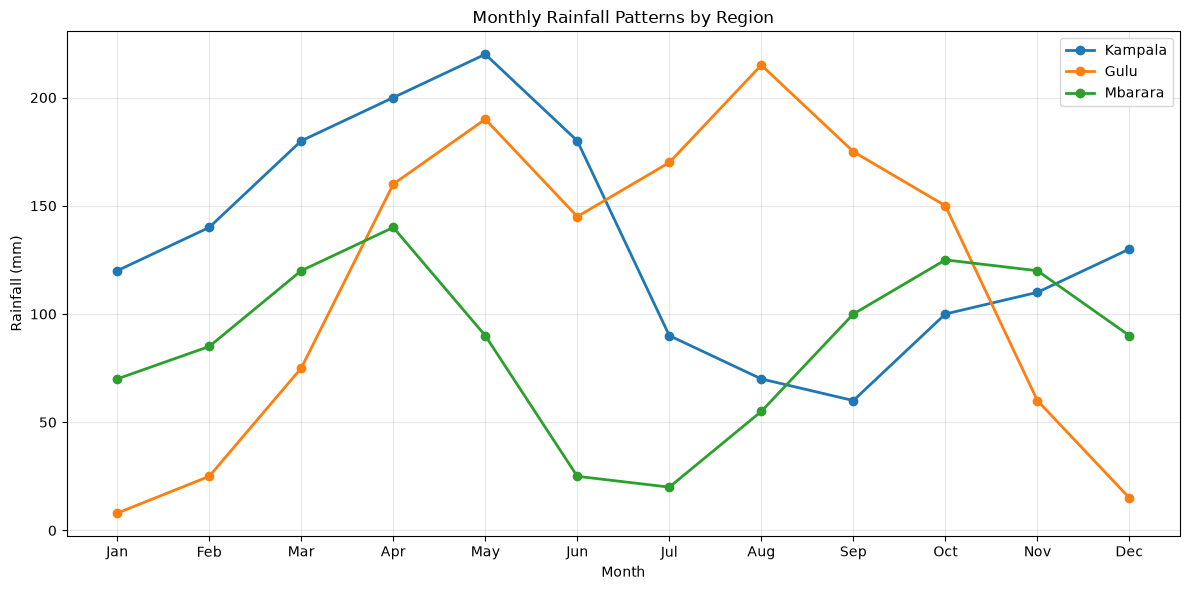

In [16]:
plt.figure(figsize=(12, 6))

for region in regions:
    plt.plot(
        MONTHS,
        region.rainfall,
        marker="o",
        linewidth=2,
        label=region.name
    )

plt.title("Monthly Rainfall Patterns by Region")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


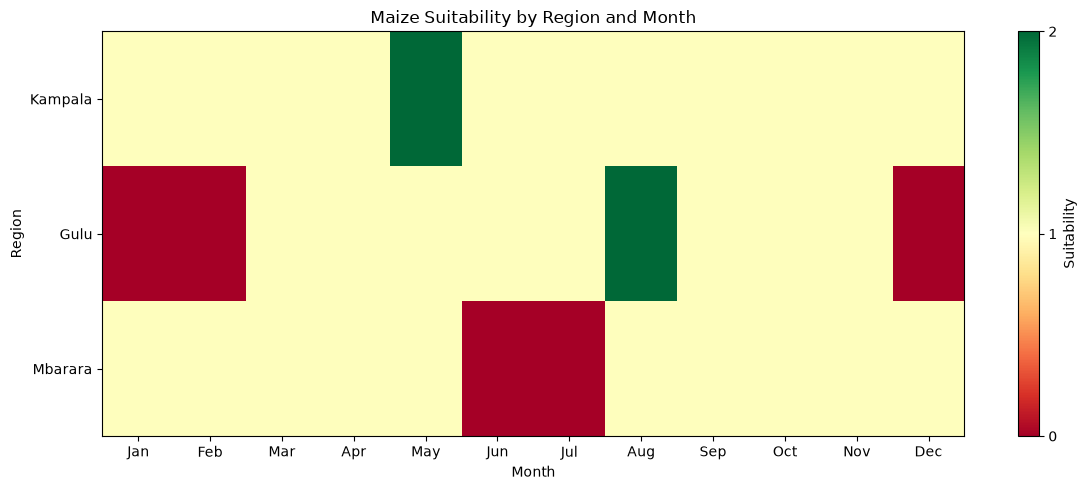

In [17]:
# Create a numerical matrix for the heatmap.
# 0 = Drought risk
# 1 = Good
# 2 = Waterlogging risk

crop_for_heatmap = "Maize"

heatmap_data = []

for region in regions:
    classifications = suitability[region.name][crop_for_heatmap]

    values = []

    for classification in classifications:
        if "Drought" in classification:
            values.append(0)
        elif "Waterlogging" in classification:
            values.append(2)
        else:
            values.append(1)

    heatmap_data.append(values)

heatmap_array = np.array(heatmap_data)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap_array,
    aspect="auto",
    cmap="RdYlGn",
    vmin=0,
    vmax=2
)

plt.colorbar(
    ticks=[0, 1, 2],
    label="Suitability"
)

plt.xticks(
    range(len(MONTHS)),
    MONTHS
)

plt.yticks(
    range(len(regions)),
    [region.name for region in regions]
)

plt.xlabel("Month")
plt.ylabel("Region")
plt.title(f"{crop_for_heatmap} Suitability by Region and Month")

plt.tight_layout()
plt.show()


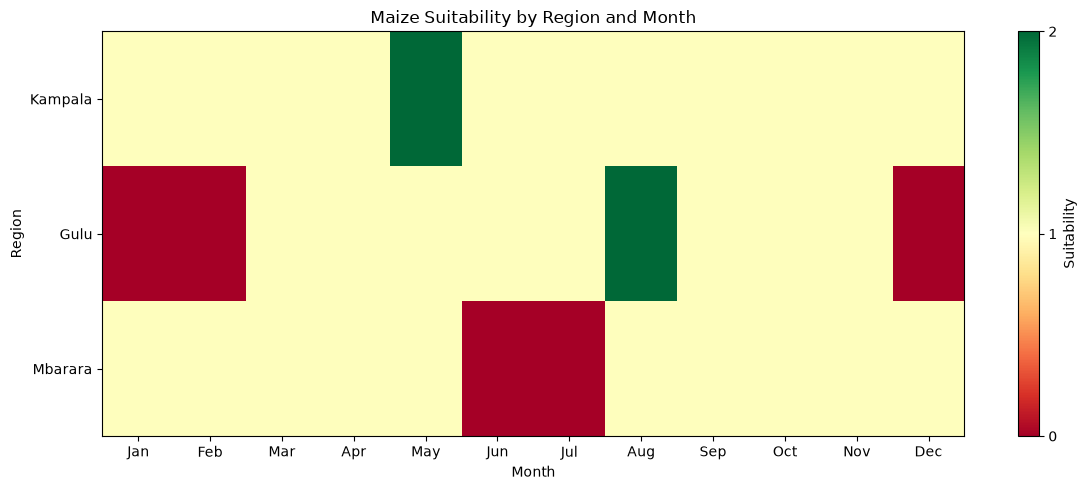

In [18]:
crop_for_heatmap = "Maize"

heatmap_data = []

for region in regions:
    classifications = suitability[region.name][crop_for_heatmap]

    values = []

    for classification in classifications:
        if "Drought" in classification:
            values.append(0)
        elif "Waterlogging" in classification:
            values.append(2)
        else:
            values.append(1)

    heatmap_data.append(values)

heatmap_array = np.array(heatmap_data)

plt.figure(figsize=(12, 5))

plt.imshow(
    heatmap_array,
    aspect="auto",
    cmap="RdYlGn",
    vmin=0,
    vmax=2
)

plt.colorbar(
    ticks=[0, 1, 2],
    label="Suitability"
)

plt.xticks(
    range(len(MONTHS)),
    MONTHS
)

plt.yticks(
    range(len(regions)),
    [region.name for region in regions]
)

plt.xlabel("Month")
plt.ylabel("Region")
plt.title(f"{crop_for_heatmap} Suitability by Region and Month")

plt.tight_layout()
plt.show()


## Task 7: Farmer Advisory Note — Gulu

### Advisory

For farmers in Gulu, maize is a suitable crop during months when rainfall is
within the assumed 50–200 mm monthly range. The rainfall data show a strong
wet period around May and another peak in August. Farmers should therefore
aim to plant maize near the beginning of a reliable rainy period, rather than
waiting until the rainfall peak itself. Based on the illustrative data, April
to May is a reasonable planting window because rainfall increases substantially
from April into May.

Beans can also be considered during months with moderate rainfall, but farmers
should avoid excessively wet periods because waterlogging can reduce crop
performance. Coffee has higher rainfall requirements and may be less suitable
during the driest months.

These recommendations are based on the illustrative monthly rainfall data and
the simplified crop thresholds used in this project. Actual planting decisions
should also consider soil type, local rainfall forecasts, seed variety,
temperature, pests and disease pressure.


## Findings & Limitations

The rainfall analysis demonstrates clear differences between the three
illustrative Ugandan regions. Kampala has the highest rainfall around May and
is classified as unimodal by the peak-detection method. Gulu shows two
important rainfall peaks in May and August, while Mbarara has peaks in April
and October, producing a bimodal classification. These results demonstrate why
regional rainfall patterns should be considered when making crop-planning
decisions.

The similarity measures provide complementary information. Cosine similarity
and Pearson correlation focus mainly on the shape of the monthly rainfall
pattern, whereas Euclidean distance is more sensitive to differences in
absolute rainfall amounts. Consequently, two regions can have similar
seasonal patterns but still receive substantially different quantities of
rainfall.

The crop-suitability analysis provides a simple decision-support framework,
but the thresholds used are simplified assumptions and should not be treated
as universal agronomic limits. The rainfall data supplied in the assignment
are also illustrative rather than long-term observations. The analysis uses
only one representative year, so it cannot measure year-to-year variability,
drought frequency or climate trends. Other factors such as soil moisture,
temperature, evapotranspiration, soil type and planting dates were not
modelled. Real NASA POWER or UNMA data covering multiple years would therefore
be needed before using the results for operational agricultural advice.
